In [2]:
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.data import Dataset
from torch.utils.data import random_split
import torchvision.transforms as transforms
from torch.utils.data import ConcatDataset

from torch.nn import functional as F
import torch.distributions as tdist


from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [4]:
mat_150 = loadmat('test_ts_nb-data_150.mat')
# mat_150 = loadmat('train_set_augmented.mat')

# val_150 = loadmat('val_ts_150_sur_base_15.mat')
val_150 = loadmat('lures.mat')

mat_test_150 = loadmat('lures_ad.mat')

c:\Users\t23arnau\Stage_teliau_arnaud\code\python\ai-intership\.venv\Lib\site-packages\scipy\io\matlab\_mio.py:236: MatReadWarning: Duplicate variable name "None" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)


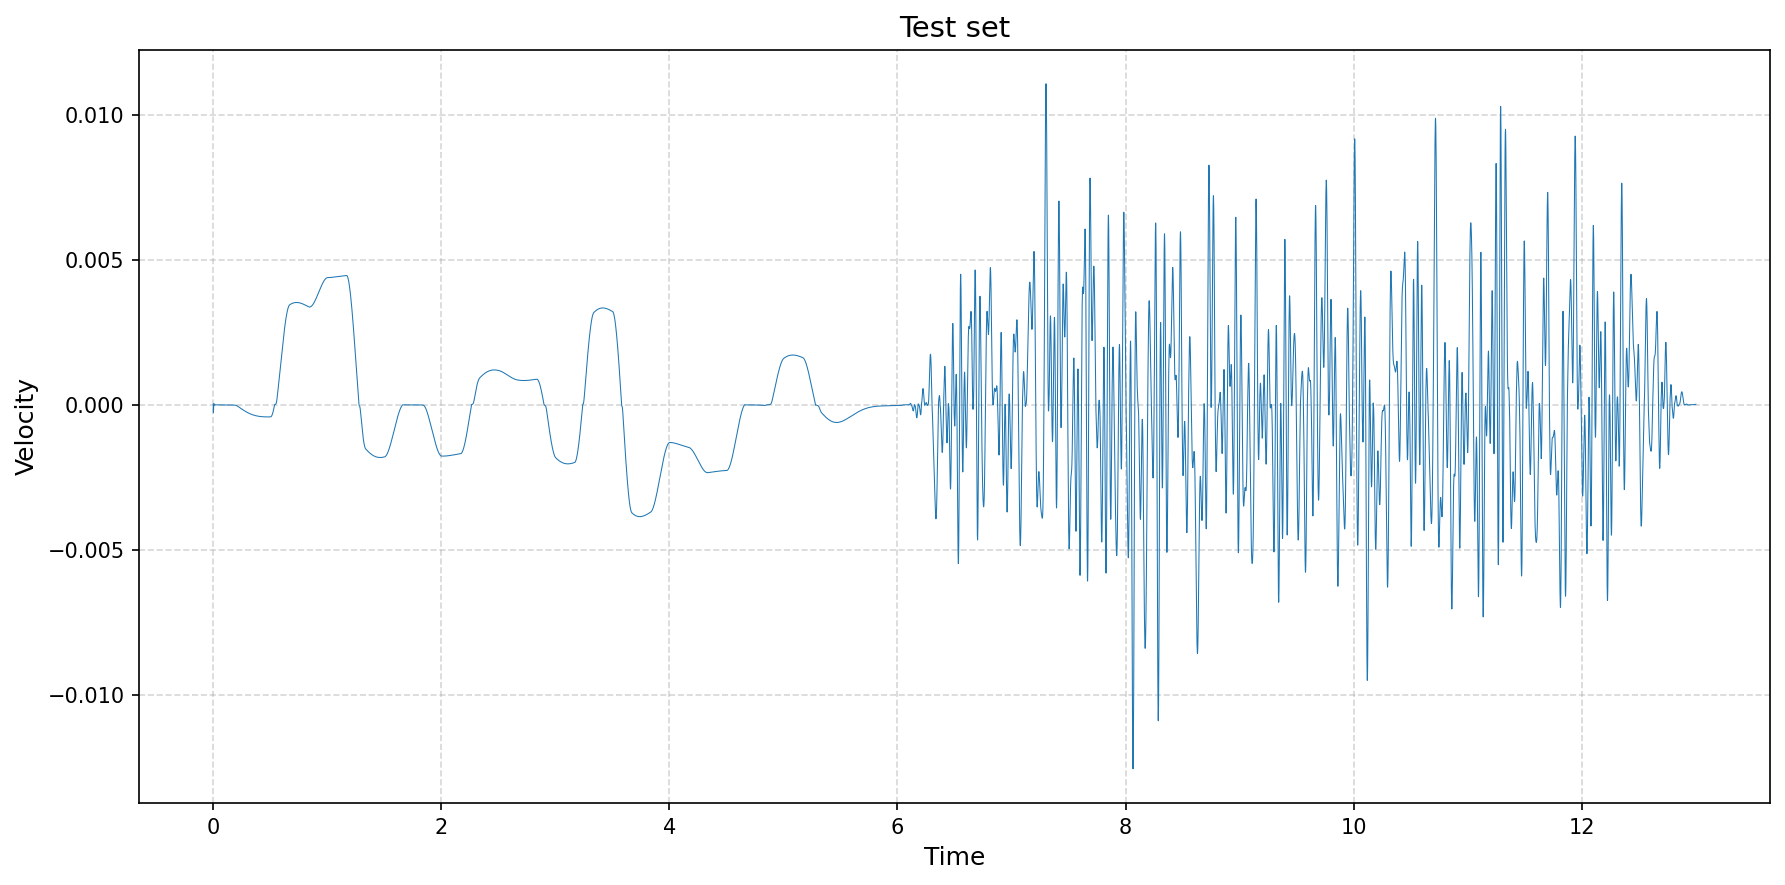

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6), dpi=150)

plt.plot(
    mat_test_150['t_f'].flatten(),
    mat_test_150['v_meas'].flatten(),
    linewidth=0.5
)

plt.xlabel('Time', fontsize=12)
plt.ylabel('Velocity', fontsize=12)
plt.title('Test set', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [7]:
from numpy import sign


def create_input(speed, pos):
    mov_aft_rev = []
    rev_flage = []

    act_speed_sign = sign(speed[0])
    initial_pos = pos[0]

    for i in range(len(speed)):
        if sign(speed[i]) != act_speed_sign:
            act_speed_sign = sign(speed[i])
            initial_pos = pos[i]
            rev_flage.append(1)
        else:
            rev_flage.append(0)

        mov_aft_rev.append(pos[i] - initial_pos)

    return mov_aft_rev, rev_flage

In [ ]:
ds_150 = []

time = mat_150['t_f'].flatten()
speed = mat_150['v_meas'].flatten()
force = mat_150['Fr_meas'].flatten()
acc = mat_150['a_meas'].flatten()
pos = mat_150['x_meas'].flatten()
pf = mat_150['prof'].flatten()

aft_rev, v_flag = create_input(speed, pos)

for j in range (len(time)-1) :
    if pf[j] != 2 and pf[j] != 3:
        ds_150.append([speed[j], force[j], acc[j], pos[j], pf[j], aft_rev[j], v_flag[j]])

df_150 = pd.DataFrame(ds_150, columns=['v_meas', 'Fr_meas', 'a_meas', 'x_meas', 'profile', 'position_after_reverse', 'reverse_flag'])

In [9]:
df_150.describe().round(2)

,v_meas,Fr_meas,a_meas,x_meas,profile,position_after_reverse,reverse_flag
count,480000.00,480000.00,480000.00,480000.00,480000.00,480000.0,480000.00
mean,-0.00,0.10,-0.00,-0.02,6.33,0.0,0.04
std,0.00,0.99,0.59,0.00,1.25,0.0,0.20
min,-0.01,-1.69,-5.81,-0.02,5.00,-0.0,0.00
25%,-0.00,-0.88,-0.01,-0.02,5.00,-0.0,0.00
50%,-0.00,0.05,0.00,-0.02,6.00,0.0,0.00
75%,0.00,1.08,0.01,-0.02,8.00,0.0,0.00
max,0.01,1.84,5.81,-0.01,8.00,0.0,1.00


In [ ]:
mean_v_150 = df_150['v_meas'].mean()
std_v_150 = df_150['v_meas'].std()

mean_a_150 = df_150['a_meas'].mean()
std_a_150 = df_150   ['a_meas'].std()

mean_x_150 = df_150['position_after_reverse'].mean()
std_x_150 = df_150['position_after_reverse'].std()

mean_Fr_150 = df_150['Fr_meas'].mean()
std_Fr_150 = df_150['Fr_meas'].std()

df_150['v_meas'] = (df_150['v_meas'] - mean_v_150) / (std_v_150)
df_150['a_meas'] = (df_150['a_meas'] - mean_a_150) / (std_a_150)
df_150['position_after_reverse'] = (df_150['position_after_reverse'] - mean_x_150) / (std_x_150)
df_150['Fr_meas'] = (df_150['Fr_meas'] - mean_Fr_150) / (std_Fr_150)

In [ ]:
dat_val_150 = []

time = val_150['t_f'].flatten()
speed = val_150['v_meas'].flatten()
force = val_150['Fr_meas'].flatten()
acc = val_150['a_meas'].flatten()
pos = val_150['x_meas'].flatten()

aft_rev, v_flag = create_input(speed, pos)

for j in range (len(time)-1) :
    dat_val_150.append([speed[j], force[j], acc[j], pos[j], aft_rev[j], v_flag[j]])

df_val_150 = pd.DataFrame(dat_val_150, columns=['v_meas', 'Fr_meas', 'a_meas', 'x_meas', 'position_after_reverse', 'reverse_flag'])

In [12]:
df_val_150.describe().round(2)

,v_meas,Fr_meas,a_meas,x_meas,position_after_reverse,reverse_flag
count,140000.00,140000.00,140000.00,140000.00,140000.00,140000.00
mean,0.00,0.23,0.00,0.00,-0.00,0.02
std,0.00,1.02,0.42,0.01,0.00,0.15
min,-0.01,-1.58,-5.81,-0.02,-0.02,0.00
25%,-0.00,-0.82,-0.01,-0.00,-0.00,0.00
50%,0.00,0.69,0.00,0.00,0.00,0.00
75%,0.00,1.18,0.01,0.01,0.00,0.00
max,0.01,1.88,5.81,0.02,0.01,1.00


In [ ]:
df_val_150['v_meas'] = (df_val_150['v_meas'] - mean_v_150) / (std_v_150)
df_val_150['a_meas'] = (df_val_150['a_meas'] - mean_a_150) / (std_a_150)
df_val_150['position_after_reverse'] = (df_val_150['position_after_reverse'] - mean_x_150) / (std_x_150)
df_val_150['Fr_meas'] = (df_val_150['Fr_meas'] - mean_Fr_150) / (std_Fr_150)

In [ ]:
dat_test_150 = []

time = mat_test_150['t_f'].flatten()
speed = mat_test_150['v_meas'].flatten()
force = mat_test_150['Fr_meas'].flatten()
acc = mat_test_150['a_meas'].flatten()
pos = mat_test_150['x_meas'].flatten()

aft_rev, v_flag = create_input(speed, pos)

for j in range (len(time)-1) :
    dat_test_150.append([speed[j], force[j], acc[j], pos[j], aft_rev[j], v_flag[j]])

df_test_150 = pd.DataFrame(dat_test_150, columns=['v_meas', 'Fr_meas', 'a_meas', 'x_meas', 'position_after_reverse', 'reverse_flag'])

In [13]:
df_test_150.describe().round(2)

,v_meas,Fr_meas,a_meas,x_meas,position_after_reverse,reverse_flag
count,13000.00,13000.00,13000.00,13000.0,13000.0,13000.00
mean,-0.00,-0.00,0.00,0.0,-0.0,0.02
std,0.00,0.97,0.25,0.0,0.0,0.14
min,-0.01,-1.25,-1.19,-0.0,-0.0,0.00
25%,-0.00,-0.86,-0.03,-0.0,-0.0,0.00
50%,-0.00,-0.78,0.00,0.0,-0.0,0.00
75%,0.00,1.11,0.03,0.0,0.0,0.00
max,0.01,1.88,1.21,0.0,0.0,1.00


In [ ]:
df_test_150['v_meas'] = (df_test_150['v_meas'] - mean_v_150) / (std_v_150)
df_test_150['a_meas'] = (df_test_150['a_meas'] - mean_a_150) / (std_a_150)
df_test_150['position_after_reverse'] = (df_test_150['position_after_reverse'] - mean_x_150) / (std_x_150)
df_test_150['Fr_meas'] = (df_test_150['Fr_meas'] - mean_Fr_150) / (std_Fr_150)

In [16]:
class TimeSeriesDataset_LSTM(Dataset):

    def __init__(self, df, window=500):
        self.window = window

        self.features = df[['v_meas']].to_numpy(
            dtype=np.float32
        )


        # self.features = df[['v_meas', 'a_meas']].to_numpy(
        #     dtype=np.float32
        # )

        # self.features = df[['v_meas', 'position_after_reverse', 'reverse_flag']].to_numpy(
        #     dtype=np.float32
        # )

        # self.features = df[['v_meas', 'a_meas', 'position_after_reverse', 'reverse_flag']].to_numpy(
        #     dtype=np.float32
        # )

        self.targets = df['Fr_meas'].to_numpy(
            dtype=np.float32
        )

    def __len__(self):
        return len(self.features) - self.window + 1

    def __getitem__(self, idx):

        x = self.features[idx:idx+self.window]
        y = self.targets[idx+self.window-1]

        return (
            torch.from_numpy(x),
            torch.tensor([y], dtype=torch.float32)
        )

In [17]:
class LSTMRegressor(nn.Module):
    def __init__(self,
                 input_size,
                 hidden_size,
                 num_layers,
                 output_size):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x : (batch, seq_len, input_size)

        out, (h, c) = self.lstm(x)

        # dernier instant temporel
        last = out[:, -1, :]

        y = self.fc(last)

        return y


class extracting_LSTM_regressor(nn.Module):
    def __init__(self,
                 input_size,
                 hidden_size,
                 num_layers,
                 output_size):
        super().__init__()

        self.extract = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),)

        self.lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x : (batch, seq_len, input_size)

        x = self.extract(x)

        out, (h, c) = self.lstm(x)

        # dernier instant temporel
        last = out[:, -1, :]

        y = self.fc(last)

        return y

# class paper_LSTM_regressor(nn.Module):
#     def __init__(self,
#                  input_size,
#                  hidden_size,
#                  num_layers,
#                  output_size):
#         super().__init__()

#         self.h0 = torch.zeros(2, batch_size = 32, hidden_size - 2, device=self.device)

#         self.extract = nn.Sequential(
#             nn.Linear(input_size, hidden_size),
#             nn.ReLU(),
#             nn.Linear(hidden_size, hidden_size)
#             nn.ReLU(),)

#         self.lstm = nn.LSTM(
#             input_size=hidden_size+1,
#             hidden_size=hidden_size,
#             num_layers=num_layers,
#             batch_first=True
#         )

#         self.fc = nn.Linear(hidden_size, output_size)

#     def forward(self, x):
#         # x : (batch, seq_len, input_size)
#         h = self.h0

#         for i in range (len(x[1])):

        
#             xh2 = self.extract(x[:][i][:-1]+h)

#             out, (hi, c) = self.lstm(xh2 + x[:][i][-1])

#             # dernier instant temporel
#             h = out[:, -1, :]

#         y = self.fc(xh2)

#         return y
    
class GRURegressor(nn.Module):
    def __init__(self,
                 input_size,
                 hidden_size,
                 num_layers,
                 output_size):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x : (batch, seq_len, input_size)

        out, h = self.gru(x)

        # dernier instant temporel
        last = out[:, -1, :]

        y = self.fc(last)

        return y

In [18]:
def create_model_LSTM(x, input=2):

    print(f"Création du modèle LSTM avec {x} entrées")

    LSTM_model = LSTMRegressor(
        input_size=input,
        hidden_size=32,
        num_layers=2,
        output_size=1
    )

    for param in LSTM_model.parameters():
        param.requires_grad = True

    return LSTM_model

def create_model_LSTM_extract(x, input=2):

    print(f"Création du modèle LSTM avec {x} entrées")

    LSTM_model = extracting_LSTM_regressor(
        input_size=input,
        hidden_size=32,
        num_layers=2,
        output_size=1
    )

    for param in LSTM_model.parameters():
        param.requires_grad = True

    return LSTM_model

def create_model_GRU(x):

    print(f"Création du modèle GRU avec {x} entrées")

    GRU_model = GRURegressor(
        input_size=2,
        hidden_size=32,
        num_layers=2,
        output_size=1
    )

    for param in GRU_model.parameters():
        param.requires_grad = True

    return GRU_model




def train_model_LSTM(train_loader_model3, val_loader_model3, LSTM_model, optimizer, criterion, scheduler, scheduler_):
    n_epochs = 200
    patience = 50
    counter = 0
    best_val_loss = float('inf')

    for epoch in range(n_epochs):

        LSTM_model.train()
        running_loss = 0.0
        for inputs, aims in train_loader_model3:
            inputs, aims = inputs.to(device), aims.to(device)
            
            optimizer.zero_grad()
            
            outputs = LSTM_model(inputs)
            loss = criterion(outputs, aims)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()

        LSTM_model.eval()
        val_loss = 0.0
        with torch.no_grad():
            val_loss = 0.0
            for val_inputs, val_aims in val_loader_model3:
                val_inputs, val_aims = val_inputs.to(device), val_aims.to(device)
                val_outputs = LSTM_model(val_inputs)
                val_loss += criterion(val_outputs, val_aims).item()

        val_loss = val_loss / len(val_loader_model3)
        scheduler.step(val_loss)
        scheduler_.step()
        print(f'Epoch {epoch+1}/{n_epochs}, Loss: {running_loss/len(train_loader_model3):.6f}, Val Loss: {val_loss:.6f}')

            # Sauvegarde du meilleur modèle
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            counter = 0

            torch.save({
                'epoch': epoch,
                'model_state_dict': LSTM_model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_loss': best_val_loss
            }, "best_model_kfold.pth")

            print("✓ Nouveau meilleur modèle sauvegardé")
        
        else:
            counter += 1

        if counter >= patience:
            for param_group in optimizer.param_groups:
                print(f"Learning rate a été ajusté à {param_group['lr']:.6f}")
            print("Early stopping déclenché")
            torch.save({
                'epoch': epoch,
                'model_state_dict': LSTM_model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_loss': best_val_loss
            }, "best_model_kfold_last.pth")
            break

    print('Training complete')
    

In [19]:
def test_model_LSTM(test_loader_model3, LSTM_model, std_Fr, mean_Fr):

# Mettre le modèle en mode évaluation
    LSTM_model.eval()

# Listes pour stocker les vraies valeurs et les prédictions
    y_true = []
    y_pred = []

    # Désactivation du calcul des gradients
    with torch.no_grad():
        for X_batch, y_batch in test_loader_model3:

            # Envoi sur GPU si disponible
            X_batch = X_batch.to(device)

            # Prédiction
            outputs = LSTM_model(X_batch)

            # Conversion en numpy
            predictions = outputs.cpu().numpy()

            y_pred.extend(predictions.flatten())
            y_true.extend(y_batch.numpy().flatten())

    # Conversion en tableaux numpy
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mse_n = mean_squared_error(y_true, y_pred)

    y_pred_ad = y_pred*std_Fr + mean_Fr
    y_true_ad = y_true*std_Fr + mean_Fr

    # Calcul des métriques
    mse = mean_squared_error(y_true_ad, y_pred_ad)

    mae = max(abs(y_true_ad - y_pred_ad))

    fit = 0
    mean = np.mean(y_true_ad)

    mean_list = np.full(len(y_pred_ad), mean) 
    fit = 1 - np.sqrt(mse)/np.sqrt(mean_squared_error(y_true_ad, mean_list))
    fitp = fit * 100

    return mse_n, mse, fitp , (mse_n)**(1/2), (mse)**(1/2), mae

## MLP ##

In [30]:
class TimeSeriesDataset_MLP(Dataset):

    def __init__(self, df, window=500):
        self.window = window

        # self.features = df[['v_meas']].to_numpy(
        #     dtype=np.float32
        # )


        # self.features = df[['v_meas', 'a_meas']].to_numpy(
        #     dtype=np.float32
        # )

        # self.features = df[['v_meas', 'position_after_reverse', 'reverse_flag']].to_numpy(
        #     dtype=np.float32
        # )

        self.features = df[['v_meas', 'a_meas', 'position_after_reverse', 'reverse_flag']].to_numpy(
            dtype=np.float32
        )

        self.targets = df['Fr_meas'].to_numpy(
            dtype=np.float32
        )

    def __len__(self):
        return len(self.features) - self.window + 1

    def __getitem__(self, idx):

        x = self.features[idx:idx+self.window]
        y = self.targets[idx+self.window-1]

        return (
            torch.from_numpy(x).reshape(-1),
            torch.tensor([y], dtype=torch.float32)
        )

In [21]:
def create_model(x, input=2):

    print(f"Création du modèle MLP avec {x} entrées")

    MLP_XD_model = nn.Sequential(
        nn.Linear(input*x, 256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        #nn.Dropout(0.2),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    )

    for param in MLP_XD_model.parameters():
        param.requires_grad = True

    return MLP_XD_model




def train_model(train_loader_model3, val_loader_model3, MLP_XD_model, optimizer, criterion, scheduler, scheduler_):
    n_epochs = 100
    patience = 20
    counter = 0
    best_val_loss = float('inf')

    for epoch in range(n_epochs):

        MLP_XD_model.train()
        running_loss = 0.0
        for inputs, aims in train_loader_model3:
            inputs, aims = inputs.to(device), aims.to(device)
            
            optimizer.zero_grad()
            
            outputs = MLP_XD_model(inputs)
            loss = criterion(outputs, aims)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()

        MLP_XD_model.eval()
        val_loss = 0.0
        with torch.no_grad():
            val_loss = 0.0
            for val_inputs, val_aims in val_loader_model3:
                val_inputs, val_aims = val_inputs.to(device), val_aims.to(device)
                val_outputs = MLP_XD_model(val_inputs)
                val_loss += criterion(val_outputs, val_aims).item()

        val_loss = val_loss / len(val_loader_model3)
        scheduler.step(val_loss)
        scheduler_.step()
        print(f'Epoch {epoch+1}/{n_epochs}, Loss: {running_loss/len(train_loader_model3):.6f}, Val Loss: {val_loss:.6f}')

            # Sauvegarde du meilleur modèle
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            counter = 0

            torch.save({
                'epoch': epoch,
                'model_state_dict': MLP_XD_model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_loss': best_val_loss
            }, "best_model_kfold.pth")

            print("✓ Nouveau meilleur modèle sauvegardé")
        
        else:
            counter += 1

        if counter >= patience:
            for param_group in optimizer.param_groups:
                print(f"Learning rate a été ajusté à {param_group['lr']:.6f}")
            print("Early stopping déclenché")
            break

    print('Training complete')
    

In [22]:
def test_model_MLP(test_loader_model3, MLP_model, std_Fr, mean_Fr):

# Mettre le modèle en mode évaluation
    MLP_model.eval()

# Listes pour stocker les vraies valeurs et les prédictions
    y_true = []
    y_pred = []

    # Désactivation du calcul des gradients
    with torch.no_grad():
        for X_batch, y_batch in test_loader_model3:

            # Envoi sur GPU si disponible
            X_batch = X_batch.to(device)

            # Prédiction
            outputs = MLP_model(X_batch)

            # Conversion en numpy
            predictions = outputs.cpu().numpy()

            y_pred.extend(predictions.flatten())
            y_true.extend(y_batch.numpy().flatten())

    # Conversion en tableaux numpy
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mse_n = mean_squared_error(y_true, y_pred)

    y_pred_ad = y_pred*std_Fr + mean_Fr
    y_true_ad = y_true*std_Fr + mean_Fr

    # Calcul des métriques
    mse = mean_squared_error(y_true_ad, y_pred_ad)

    mae = max(abs(y_true_ad - y_pred_ad))

    fit = 0
    mean = np.mean(y_true_ad)

    mean_list = np.full(len(y_pred_ad), mean) 
    fit = 1 - np.sqrt(mse)/np.sqrt(mean_squared_error(y_true_ad, mean_list))
    fitp = fit * 100

    return mse_n, mse, fitp , (mse_n)**(1/2), (mse)**(1/2), mae

## END ##

In [ ]:
metric = []

x=500

pf_df = {}


df_train = TimeSeriesDataset_LSTM(df_150, window=x)
df_val   = TimeSeriesDataset_LSTM(df_val_150, window=x)
df_test  = TimeSeriesDataset_LSTM(df_test_150, window=x)

# df_train = TimeSeriesDataset_MLP(df_150, window=x)
# df_val   = TimeSeriesDataset_MLP(df_val_150, window=x)
# df_test  = TimeSeriesDataset_MLP(df_test_150, window=x)

tr_load = DataLoader(
    df_train,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

vl_load = DataLoader(
    df_val,
    batch_size=32,
    shuffle=False
)

te_load = DataLoader(
    df_test,
    batch_size=32,
    shuffle=False
)

    # créa modèle
LSTM_model = create_model_LSTM(x, input=1)
# LSTM_model = create_model(x, input=4)
LSTM_model.to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(LSTM_model.parameters(), lr=0.001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=5
)

scheduler_ = torch.optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[10, 20, 40, 60, 80, 100, 120, 140, 160, 180, 200, 220],
    gamma=0.5
)


# entraînement
train_model_LSTM(tr_load, vl_load, LSTM_model, optimizer, criterion, scheduler, scheduler_)
# train_model(tr_load, vl_load, LSTM_model, optimizer, criterion, scheduler, scheduler_)

# récup model
checkpoint = torch.load("best_model_kfold.pth")

LSTM_model.load_state_dict(checkpoint['model_state_dict'])

# evaluation
mse_n, mse, fitp, rmse_n, rmse, mae = test_model_LSTM(te_load, LSTM_model, std_Fr_150, mean_Fr_150)
# mse_n, mse, fitp, rmse_n, rmse, mae = test_model_MLP(te_load, LSTM_model, std_Fr_150, mean_Fr_150)

# récup métrique

print(f"MSE_normed : {mse_n:.6f}")
print(f"MSE : {mse:.6f}")
print(f"Fit : {fitp:.6f}")

# checkpoint = torch.load("best_model_kfold_last.pth")

# LSTM_model.load_state_dict(checkpoint['model_state_dict'])

# # evaluation
# # mse_n, mse, fitp, rmse_n, rmse, mae = test_model_LSTM(te_load, LSTM_model, std_Fr_150, mean_Fr_150)
# mse_n, mse, fitp, rmse_n, rmse, mae = test_model_MLP(te_load, LSTM_model, std_Fr_150, mean_Fr_150)
# # récup métrique
# print(f"MSE_normed(der) : {mse_n:.6f}")
# print(f"MSE(der) : {mse:.6f}")
# print(f"Fit(der) : {fitp:.6f}")



Création du modèle MLP avec 500 entrées
Epoch 1/100, Loss: 0.035918, Val Loss: 0.853855
✓ Nouveau meilleur modèle sauvegardé
Epoch 2/100, Loss: 0.010924, Val Loss: 0.631296
✓ Nouveau meilleur modèle sauvegardé
Epoch 3/100, Loss: 0.008076, Val Loss: 1.106013
Epoch 4/100, Loss: 0.006702, Val Loss: 0.919767
Epoch 5/100, Loss: 0.005823, Val Loss: 0.464546
✓ Nouveau meilleur modèle sauvegardé
Epoch 6/100, Loss: 0.005114, Val Loss: 0.809551
Epoch 7/100, Loss: 0.004665, Val Loss: 67.304422
Epoch 8/100, Loss: 0.004353, Val Loss: 0.852663
Epoch 9/100, Loss: 0.004308, Val Loss: 5.914435
Epoch 10/100, Loss: 0.003962, Val Loss: 1.849220
Epoch 11/100, Loss: 0.002686, Val Loss: 4.974114
Epoch 12/100, Loss: 0.002095, Val Loss: 6.665052
Epoch 13/100, Loss: 0.001936, Val Loss: 20.588516
Epoch 14/100, Loss: 0.001834, Val Loss: 16.524504
Epoch 15/100, Loss: 0.001758, Val Loss: 22.037607
Epoch 16/100, Loss: 0.001707, Val Loss: 29.598143
Epoch 17/100, Loss: 0.001655, Val Loss: 19.793059
Epoch 18/100, Loss:

In [32]:
X, y = next(iter(te_load))

print("X :", X.shape)
print("y :", y.shape)

X : torch.Size([32, 2000])
y : torch.Size([32, 1])


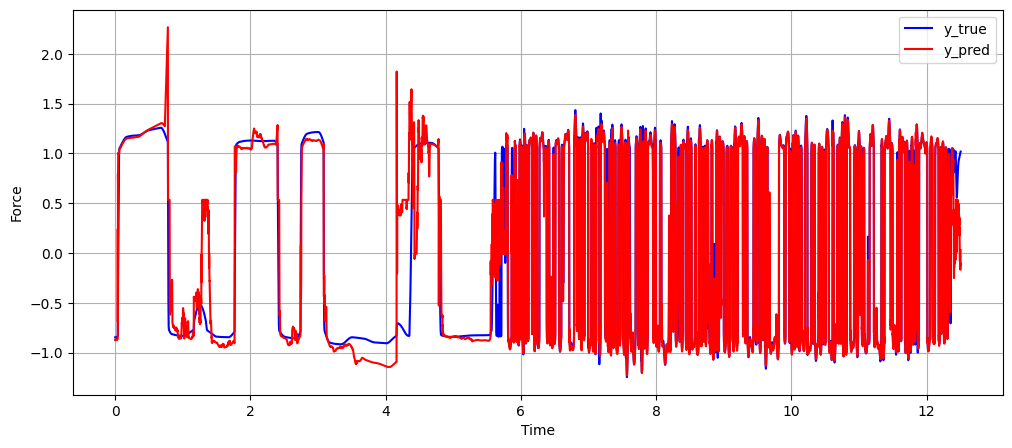

In [33]:
y_true_ad = []
y_pred_ad = []

checkpoint = torch.load("best_model_kfold.pth")

LSTM_model.load_state_dict(checkpoint['model_state_dict'])

# Désactivation du calcul des gradients
with torch.no_grad():
    for X_batch, y_batch in te_load:

        # Envoi sur GPU si disponible
        X_batch = X_batch.to(device)

        # Prédiction
        outputs = LSTM_model(X_batch)

        # Conversion en numpy
        predictions = outputs.cpu().numpy()

        y_pred_ad.extend(predictions.flatten())
        y_true_ad.extend(y_batch.numpy().flatten())

# Conversion en tableaux numpy
y_true_ad = np.array(y_true_ad)
y_pred_ad = np.array(y_pred_ad)



y_pred_ad = y_pred_ad*std_Fr_150 + mean_Fr_150
y_true_ad = y_true_ad*std_Fr_150 + mean_Fr_150

y_true_ad = np.asarray(y_true_ad).flatten()
y_pred_ad = np.asarray(y_pred_ad).flatten()

plt.figure(figsize=(12, 5))
plt.plot(mat_test_150['t_f'].flatten()[1:-1*x+1], y_true_ad, 'b', label='y_true')
plt.plot(mat_test_150['t_f'].flatten()[1:-1*x+1], y_pred_ad, 'r', label='y_pred')
plt.xlabel('Time')
plt.ylabel('Force')
plt.legend()
plt.grid(True)
plt.show()

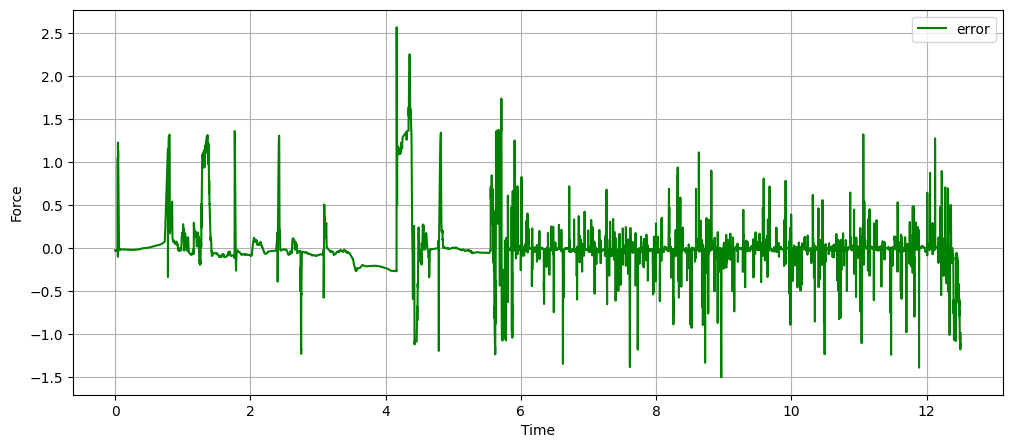

In [34]:
plt.figure(figsize=(12, 5))
plt.plot(mat_test_150['t_f'].flatten()[1:-1*x+1], y_pred_ad- y_true_ad, 'g', label='error')
plt.xlabel('Time')
plt.ylabel('Force')
plt.legend()
plt.grid(True)
plt.show()